
### Importing Dependencies

In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import warnings
import matplotlib.collections
import matplotlib.cm as cm

BERLIN_CMAP = cm.get_cmap('berlin')


from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

from sklearn.model_selection import KFold

# ML Models
from sklearn.ensemble import (
    VotingRegressor,
    RandomForestRegressor,
    ExtraTreesRegressor,
    GradientBoostingRegressor,
    AdaBoostRegressor,
    BaggingRegressor
)

from sklearn.linear_model import (
    LinearRegression,
    Ridge,
    Lasso,
    ElasticNet
)

from sklearn.tree import DecisionTreeRegressor
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor
from sklearn.neural_network import MLPRegressor

from catboost import CatBoostRegressor

warnings.filterwarnings("ignore")

### TGA Data Setting

In [11]:
# Training particle sizes
train_sizes = [200, 600, 850]

# Heating rates used for training/testing
heating_rates = [10, 20, 40]

# Completely unseen test particle size
TEST_SIZE = 400

# Minimum number of points among the datasets
TARGET_ROWS = 670

print("Current directory:")
print(os.getcwd())

print("\nTarget rows per TGA curve:", TARGET_ROWS)

Current directory:
c:\Users\SONALIKA\Downloads\Guava TGA

Target rows per TGA curve: 670


### Load TGA file

In [12]:
def load_tga_file(filename, size, heating_rate):
    data = []

    with open(filename, 'r', encoding='latin1') as f:
        for line in f.readlines()[1:]:
            if line.strip() and not line.startswith(('MICS', 'Index')):
                p = line.split()
                if len(p) == 6:
                    try: data.append([float(x) for x in p])
                    except ValueError: pass

    if not data:
        raise ValueError(f"No valid data found in {filename}")

    df = pd.DataFrame(data, columns=['Index','Ts','t','HF','Weight','Tr'])
    df = df.sort_values('Ts').drop_duplicates('Ts')

    df['mass_percent'] = df.Weight / df.Weight.iloc[5:15].mean() * 100
    df['size'] = size
    df['heating_rate'] = heating_rate

    return df.reset_index(drop=True)

### Resampling each to 670 points

In [13]:
def resample_tga_curve(df, target_rows=670):
    df = df.sort_values('Ts').drop_duplicates('Ts').reset_index(drop=True)

    old_Ts = df.Ts.values
    new_Ts = np.linspace(old_Ts.min(), old_Ts.max(), target_rows)

    new_df = pd.DataFrame({'Ts': new_Ts})

    for col in ['t','HF','Weight','Tr','mass_percent']:
        new_df[col] = np.interp(new_Ts, old_Ts, df[col].values)

    new_df['size'] = df['size'].iloc[0]
    new_df['heating_rate'] = df['heating_rate'].iloc[0]
    new_df['Index'] = np.arange(target_rows)

    return new_df[
        ['Index','Ts','t','HF','Weight','Tr',
         'mass_percent','size','heating_rate']
    ].reset_index(drop=True)

### Load + Resample Training data

In [14]:
print("="*50)
print("LOADING TRAINING DATA")

train_dfs = []

for size in train_sizes:
    for rate in heating_rates:
        filename = f"g-{size}-{rate}.txt"
        print(f"\n{filename}")

        df = load_tga_file(filename, size, rate)
        print(f"Original: {len(df)}")

        df = resample_tga_curve(df, TARGET_ROWS)
        print(f"Resampled: {len(df)}")

        train_dfs.append(df)

train_data = pd.concat(train_dfs, ignore_index=True)

print("\n" + "="*50)
print("TRAINING DATA COMPLETE")
print(f"Curves       : {len(train_dfs)}")
print(f"Rows/curve   : {TARGET_ROWS}")
print(f"Total rows   : {len(train_data)}")
print(f"Expected rows: {len(train_dfs)*TARGET_ROWS}")

LOADING TRAINING DATA

g-200-10.txt
Original: 4021
Resampled: 670

g-200-20.txt
Original: 2011
Resampled: 670

g-200-40.txt
Original: 1006
Resampled: 670

g-600-10.txt
Original: 4021
Resampled: 670

g-600-20.txt
Original: 2011
Resampled: 670

g-600-40.txt
Original: 1006
Resampled: 670

g-850-10.txt
Original: 4021
Resampled: 670

g-850-20.txt
Original: 2011
Resampled: 670

g-850-40.txt
Original: 1006
Resampled: 670

TRAINING DATA COMPLETE
Curves       : 9
Rows/curve   : 670
Total rows   : 6030
Expected rows: 6030


### Load + Resample Test data

In [15]:
print("="*50)
print("LOADING 400 µm TEST DATA")

test_dfs_400 = []

for rate in heating_rates:
    filename = f"g-400-{rate}.txt"

    if not os.path.exists(filename):
        print(f"Skipped: {filename}")
        continue

    df = load_tga_file(filename, 400, rate)
    print(f"\n{filename} → Original: {len(df)}")

    df = resample_tga_curve(df, TARGET_ROWS)
    print(f"             Resampled: {len(df)}")

    test_dfs_400.append(df)

if not test_dfs_400:
    raise ValueError("No 400 µm test files were loaded.")

test_data_400 = pd.concat(test_dfs_400, ignore_index=True)

print("\n" + "="*50)
print("400 µm TEST DATA COMPLETE")
print(f"Curves     : {len(test_dfs_400)}")
print(f"Total rows : {len(test_data_400)}")
print("\nRows/curve:")
print(test_data_400.groupby(['size','heating_rate']).size())

LOADING 400 µm TEST DATA

g-400-10.txt → Original: 4621
             Resampled: 670

g-400-20.txt → Original: 2311
             Resampled: 670

g-400-40.txt → Original: 1306
             Resampled: 670

400 µm TEST DATA COMPLETE
Curves     : 3
Total rows : 2010

Rows/curve:
size  heating_rate
400   10              670
      20              670
      40              670
dtype: int64


### Verify Sampling

In [16]:

print("\nTRAINING CURVES")
print(
    train_data
    .groupby(['size', 'heating_rate'])
    .size()
)

print("\n400 µm TEST CURVES")
print(
    test_data_400
    .groupby(['size', 'heating_rate'])
    .size()
)


TRAINING CURVES
size  heating_rate
200   10              670
      20              670
      40              670
600   10              670
      20              670
      40              670
850   10              670
      20              670
      40              670
dtype: int64

400 µm TEST CURVES
size  heating_rate
400   10              670
      20              670
      40              670
dtype: int64


### Verifying accuracy of resampling by plot

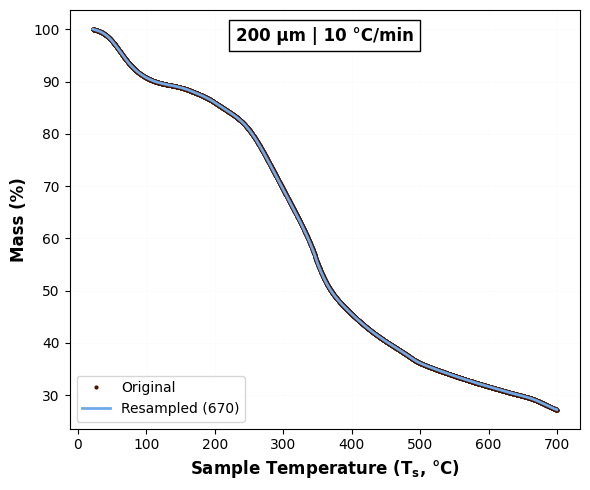

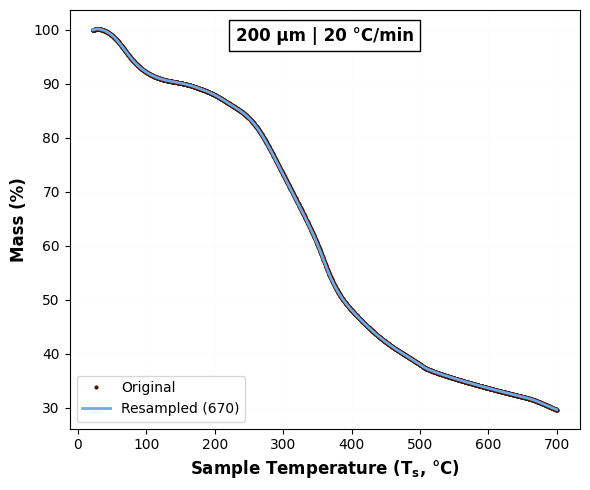

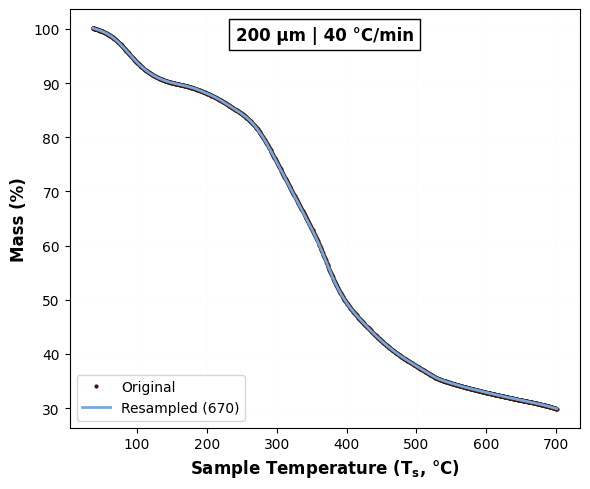

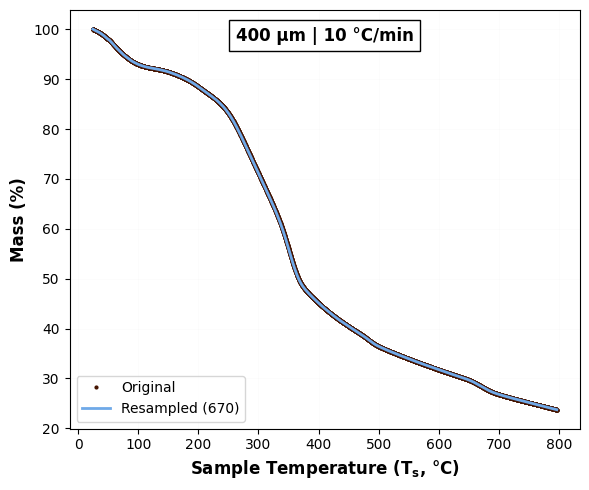

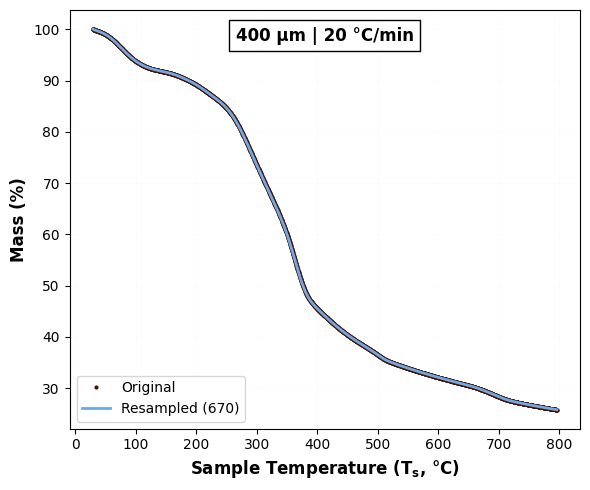

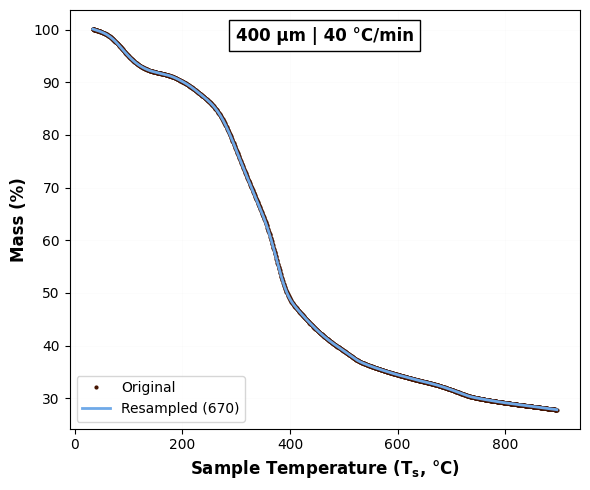

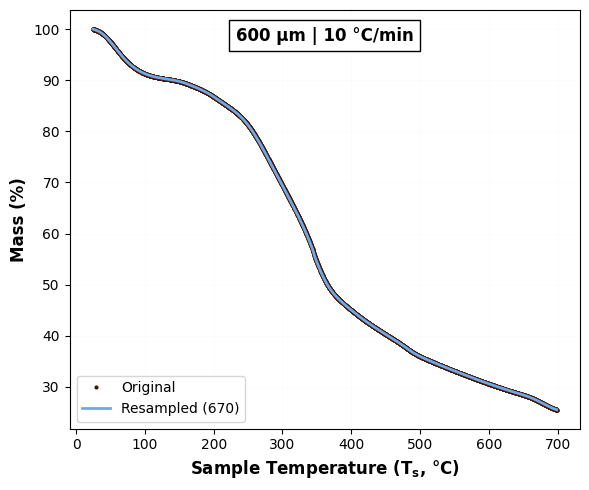

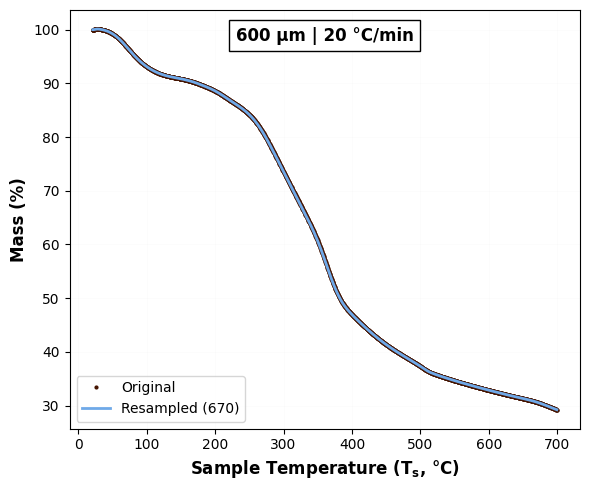

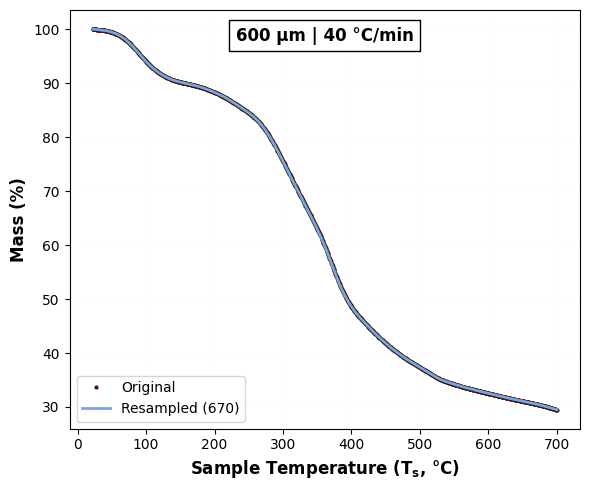

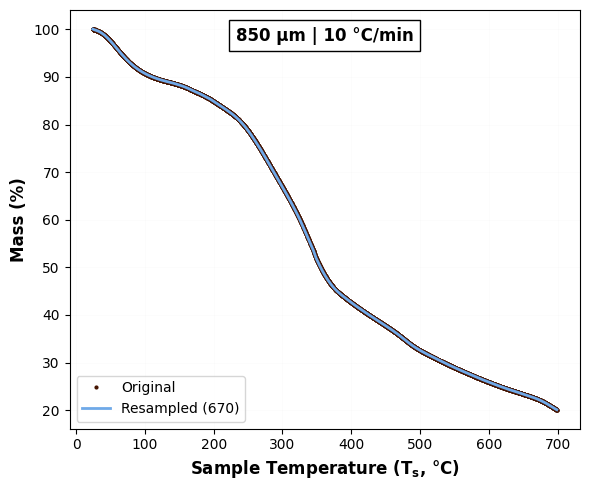

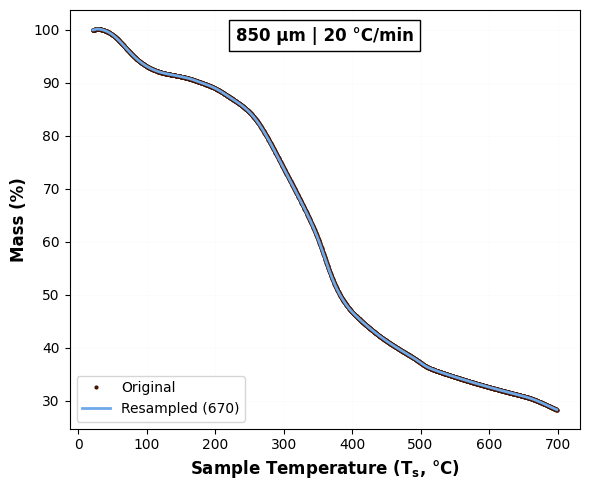

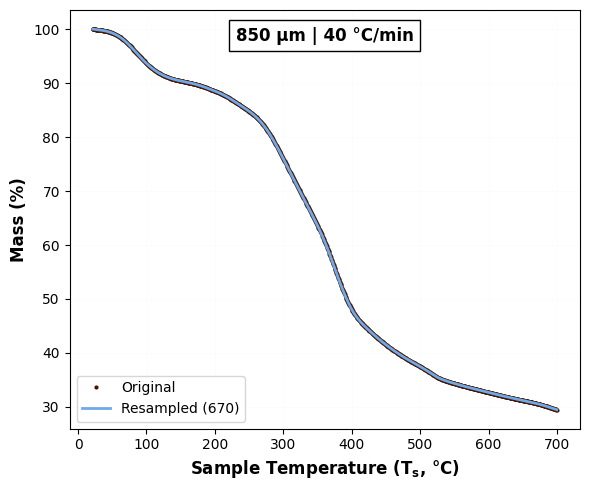

In [17]:
sizes, rates = [200, 400, 600, 850], [10, 20, 40]
_berlin_vals = np.linspace(0.08, 0.92, 4)

for size in sizes:
    for rate in rates:
        fig, a = plt.subplots(figsize=(6, 5))

        data = []
        with open(f"g-{size}-{rate}.txt", encoding="latin1") as f:
            for l in f:
                p = l.split()
                if len(p) == 6:
                    try: data.append([float(x) for x in p])
                    except: pass
        df = pd.DataFrame(
            data, columns=["Index","Ts","t","HF","Weight","Tr"]
        ).sort_values("Ts").drop_duplicates("Ts")
        df["mass_percent"] = df.Weight / df.Weight.iloc[5:15].mean() * 100
        T = np.linspace(df.Ts.min(), df.Ts.max(), 670)
        M = np.interp(T, df.Ts, df.mass_percent)

        a.plot(df.Ts, df.mass_percent, 'o', ms=2, label="Original", color=BERLIN_CMAP(_berlin_vals[2]))
        a.plot(T, M, lw=2, label="Resampled (670)", color=BERLIN_CMAP(_berlin_vals[0]))

        # --- Size + rate label INSIDE the plot, boxed ---
        a.text(
            .5, .96,
            f'{size} µm | {rate} °C/min',
            transform=a.transAxes,
            fontsize=12,
            fontweight='bold',
            ha='center', va='top',
            bbox=dict(boxstyle='square,pad=0.4', facecolor='white',
                      edgecolor='black', linewidth=1.0)
        )

        a.set_xlabel("Sample Temperature ($\mathbf{T_s}$, °C)", fontweight= 'bold', fontsize=12)
        a.set_ylabel("Mass (%)", fontweight= 'bold', fontsize=12)
        a.legend(fontsize=10, loc='lower left')
        a.grid(alpha=.03)

        plt.tight_layout()
        plt.savefig(f'tga_resample_{size}um_{rate}Cmin.png', dpi=150, bbox_inches='tight')
        plt.show()
        plt.close()

## Grouped Statistical Violin Plots

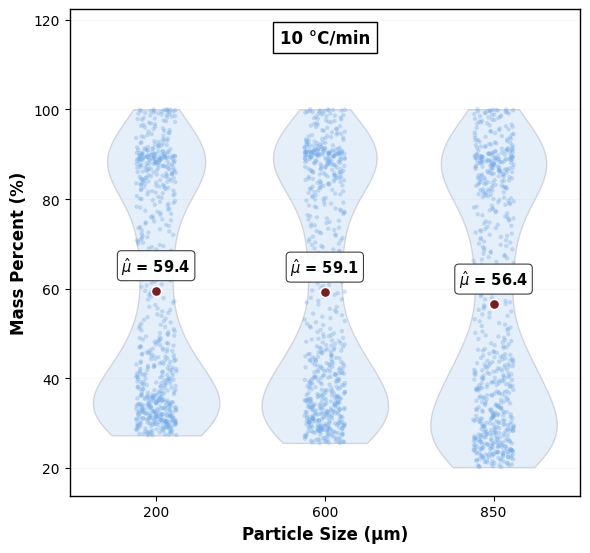

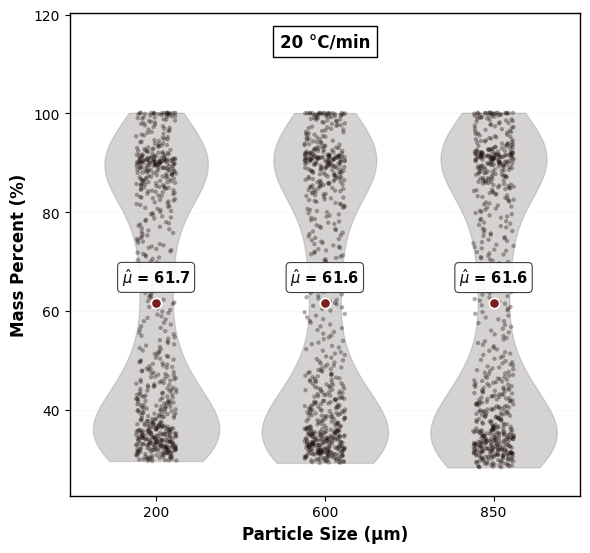

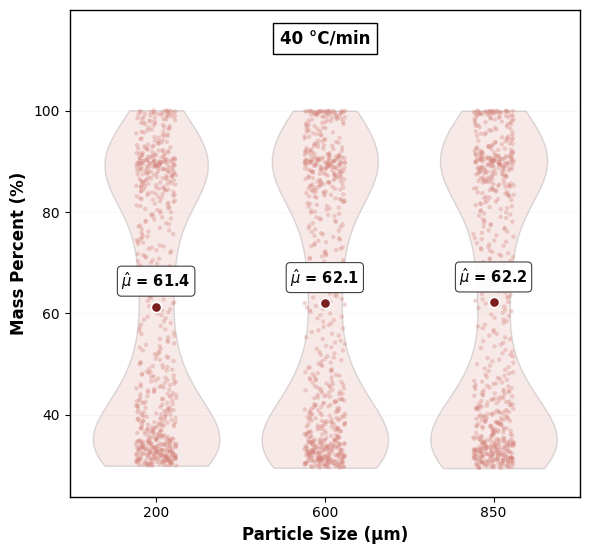

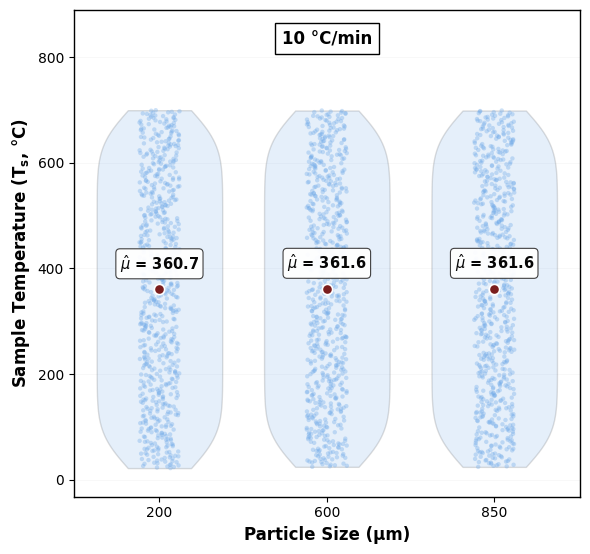

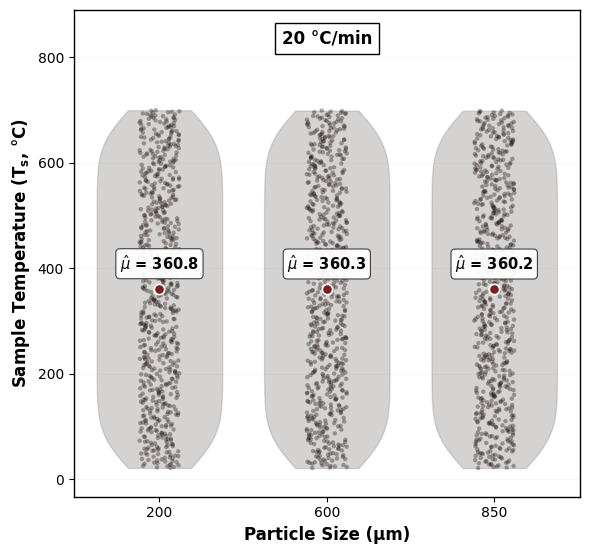

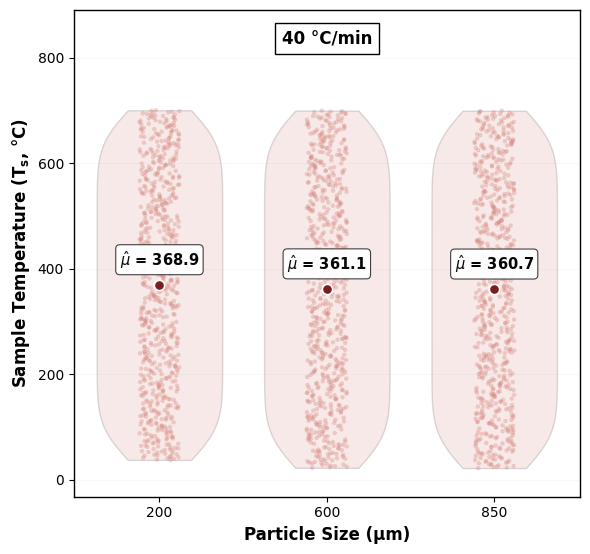

In [18]:
plt.rcParams.update({
    'font.family': 'sans-serif',
    'axes.edgecolor': '#555555',
    'axes.linewidth': 0.8,
})

rates = [10, 20, 40]
colors = [BERLIN_CMAP(x) for x in np.linspace(0.08, 0.92, len(heating_rates))]

for feature in ['mass_percent', 'Ts']:
    for rate, c in zip(rates, colors):
        fig, a = plt.subplots(figsize=(6, 6))

        a.grid(axis='y', alpha=.35, color='#ececec', linewidth=0.7)
        a.set_axisbelow(True)

        d = train_data[train_data.heating_rate == rate]
        sizes = sorted(d['size'].unique())
        data_by_size = [d[d['size'] == s][feature].values for s in sizes]
        positions = np.arange(1, len(sizes) + 1)

        # ---- headroom calc (NEW) ----
        all_vals = np.concatenate(data_by_size)
        ymin, ymax = all_vals.min(), all_vals.max()
        yrange = ymax - ymin if ymax > ymin else 1
        pad_top = yrange * 0.28   # extra headroom for label + mean annotations
        pad_bot = yrange * 0.08

        # ---- violin (distribution shape) ----
        vp = a.violinplot(
            data_by_size, positions=positions,
            showmeans=False, showextrema=False, showmedians=False,
            widths=0.75
        )
        for body in vp['bodies']:
            body.set_facecolor(c)
            body.set_edgecolor('#444444')
            body.set_linewidth(1.0)
            body.set_alpha(0.18)

        # ---- jittered points, narrow spread inside violin ----
        rng = np.random.default_rng(42)
        for pos, vals in zip(positions, data_by_size):
            jitter = rng.uniform(-0.12, 0.12, size=len(vals))
            a.scatter(pos + jitter, vals, s=10, color=c, alpha=0.35,
                      edgecolor='none', zorder=2)

        # ---- mean marker + clean label ----
        for pos, vals in zip(positions, data_by_size):
            mu = np.mean(vals)
            a.scatter(pos, mu, s=55, color='#7A1E1E', zorder=4,
                      edgecolor='white', linewidth=1.2)
            a.annotate(
                f'$\\hat{{\\mu}}$ = {mu:.1f}',
                (pos, mu), textcoords='offset points', xytext=(0, 14),
                ha='center', fontsize=10.5, fontweight='bold', color="#060606",
                bbox=dict(boxstyle='round,pad=0.28', facecolor='white',
                         edgecolor="#373636", linewidth=0.8, alpha=0.95),
                zorder=5
            )

        a.text(
                    .5, .96,
                    f'{rate} °C/min',
                    transform=a.transAxes,
                    fontsize=12,
                    fontweight='bold',
                    ha='center', va='top',
                    bbox=dict(boxstyle='square,pad=0.4', facecolor='white',
                              edgecolor='black', linewidth=1.0)
                )

        # ---- apply headroom (NEW) ----
        a.set_ylim(ymin - pad_bot, ymax + pad_top)

        a.set_xticks(positions)
        a.set_xticklabels([f'{s}' for s in sizes])
        a.set_xlabel('Particle Size (µm)', fontsize=12, fontweight='bold')
        ylabel_map = {'mass_percent': 'Mass Percent (%)',
                      'Ts': 'Sample Temperature ($\mathbf{T_s}$, °C)'}
        a.set_ylabel(ylabel_map.get(feature, feature.replace('_', ' ').title()), fontsize=12, fontweight='bold')

        for spine in a.spines.values():
            spine.set_visible(True)
            spine.set_color('black')
            spine.set_linewidth(1.0)

        plt.tight_layout(rect=[0, 0, 1, 0.94])
        plt.savefig(f'{feature}_violin_{rate}Cmin.png', dpi=200, bbox_inches='tight')
        plt.show()
        plt.close()

### Feature Engineering

In [19]:
def add_engineered_features(df):
    """
    Applies feature engineering to the dataset by adding polynomial,
    interaction, and logarithmic features.
    """
    df = df.copy()

    # 1. Polynomial Features (Non-linear relationships)
    df['Ts_sq'] = df['Ts'] ** 2
    df['size_sq'] = df['size'] ** 2
    df['heating_rate_sq'] = df['heating_rate'] ** 2

    # 2. Interaction Terms (Combined effects)
    df['Ts_rate_interaction'] = df['Ts'] * df['heating_rate']
    df['Ts_size_interaction'] = df['Ts'] * df['size']
    df['size_rate_interaction'] = df['size'] * df['heating_rate']

    # 3. Logarithmic Features (Compressing large scales)
    # Using log1p (log(1+x)) to safely handle any potential zeros
    df['log_Ts'] = np.log1p(df['Ts'])
    df['log_size'] = np.log1p(df['size'])

    return df

print("--- Applying Feature Engineering ---")
# Apply feature engineering to the training set
train_data_fe = add_engineered_features(train_data)
test_data_fe = add_engineered_features(test_data_400)


# Define the new expanded list of features
features = [
    'Ts', 'heating_rate', 'size',
    'Ts_sq', 'size_sq', 'heating_rate_sq',
    'Ts_rate_interaction', 'Ts_size_interaction', 'size_rate_interaction',
    'log_Ts', 'log_size'
]
target = 'mass_percent'

# Prepare the final Training X and y
X_train = train_data_fe[features]
y_train = train_data_fe[target]

--- Applying Feature Engineering ---


### Train Models


In [20]:
X = train_data_fe[features]
y = train_data_fe[target]

print("\nFeatures used:", list(X.columns))
print(f"X shape: {X.shape}, y shape: {y.shape}\n")

# Base models dictionary
models = {

    'Ridge': Ridge(),
    'Lasso': Lasso(),
    'LinearRegression': LinearRegression(),
    'DecisionTreeRegressor': DecisionTreeRegressor(random_state=42),
    'RandomForestRegressor': RandomForestRegressor(random_state=42, n_jobs=-1),
    'ExtraTreesRegressor': ExtraTreesRegressor(random_state=42, n_jobs=-1),
    'GradientBoostingRegressor': GradientBoostingRegressor(random_state=42),
    'AdaBoostRegressor': AdaBoostRegressor(random_state=42),
    'KNeighborsRegressor': KNeighborsRegressor(n_jobs=-1),

    'CatBoostRegressor': CatBoostRegressor(random_state=42, verbose=0)
}

# --- Voting Regressor Ensembling ---

# 1. Convert the dictionary items into a list of (name, model) tuples
ensemble_estimators = list(models.items())

# 2. Initialize the Voting Regressor (it will average the predictions of all models)
voting_ensemble = VotingRegressor(estimators=ensemble_estimators)

# 3. Append the ensemble back into your models dict
# This lets your kfold CV loop evaluate the ensemble automatically alongside individual models!
models['VotingEnsemble'] = voting_ensemble

print(f"Total models to evaluate (including ensemble): {len(models)}")



Features used: ['Ts', 'heating_rate', 'size', 'Ts_sq', 'size_sq', 'heating_rate_sq', 'Ts_rate_interaction', 'Ts_size_interaction', 'size_rate_interaction', 'log_Ts', 'log_size']
X shape: (6030, 11), y shape: (6030,)

Total models to evaluate (including ensemble): 11


### No CV model

In [21]:

features = [
    'Ts', 'size', 'heating_rate',
    'Ts_sq', 'size_sq', 'heating_rate_sq',
    'Ts_rate_interaction', 'Ts_size_interaction',
    'size_rate_interaction', 'log_Ts', 'log_size'
]
target = 'mass_percent'

X = train_data_fe[features]
y = train_data_fe[target]

results = []
predictions_store = {}   # <-- renamed from 'preds' for plotting compatibility

for name, model in models.items():

    model.fit(X, y)

    yt, yp = [], []

    for rate in [10, 20, 40]:
        df = load_tga_file(f'g-400-{rate}.txt', 400, rate)

        X_base = df[['Ts', 'size', 'heating_rate']]
        X_test = add_engineered_features(X_base)[features]

        yt.extend(df['mass_percent'].values)
        yp.extend(model.predict(X_test))

    yt, yp = np.array(yt), np.array(yp)
    mae = mean_absolute_error(yt, yp)
    r2 = r2_score(yt, yp)
    rmse = np.sqrt(mean_squared_error(yt, yp))

    results.append([name, mae, r2, rmse])

    # --- FIXED: store as dict, not a tuple ---
    predictions_store[name] = {
        "y_true": yt,
        "y_pred": yp,
        "mae": mae,
        "r2": r2,
        "RMSE": rmse,
        "error": None
    }

results_df = pd.DataFrame(
    results, columns=['Model', 'MAE', 'R2', 'RMSE']
).sort_values('MAE')

print(results_df.to_string(index=False))

best_model_name = results_df.iloc[0]['Model']
best_model_instance = models[best_model_name]

print(
    f"\n★ Champion: {best_model_name} "
    f"| MAE = {results_df.iloc[0]['MAE']:.4f} ★"
)

                    Model      MAE       R2     RMSE
        CatBoostRegressor 1.130844 0.997410 1.368037
    DecisionTreeRegressor 1.170744 0.997189 1.425082
      ExtraTreesRegressor 1.186910 0.997144 1.436390
    RandomForestRegressor 1.200150 0.997025 1.466179
GradientBoostingRegressor 1.272211 0.996622 1.562174
           VotingEnsemble 1.594949 0.994031 2.076733
        AdaBoostRegressor 1.742541 0.993309 2.198756
      KNeighborsRegressor 3.183322 0.976815 4.092867
         LinearRegression 3.283692 0.976794 4.094685
                    Ridge 3.285888 0.976775 4.096423
                    Lasso 5.786178 0.938300 6.676768

★ Champion: CatBoostRegressor | MAE = 1.1308 ★


### Models Parity Plots


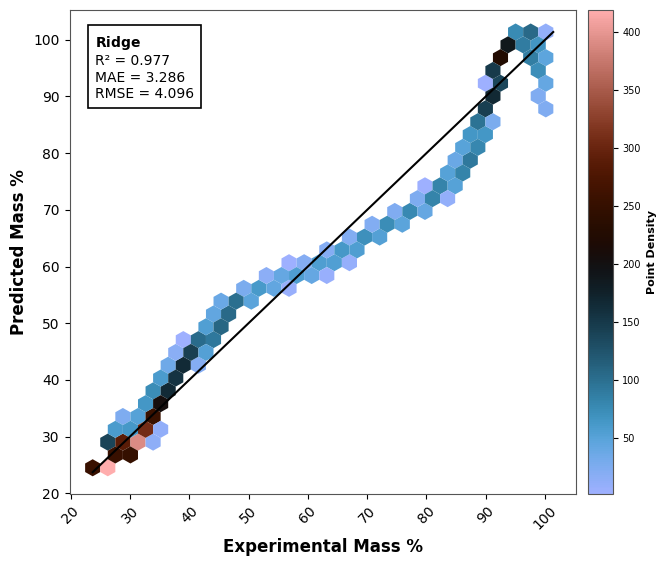

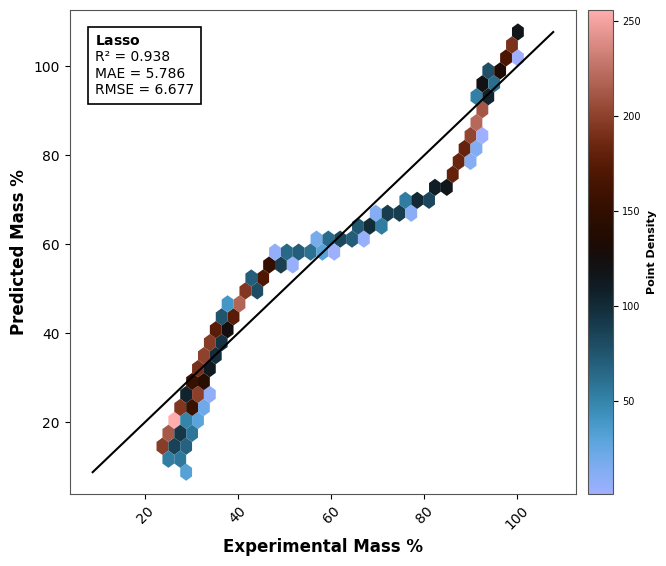

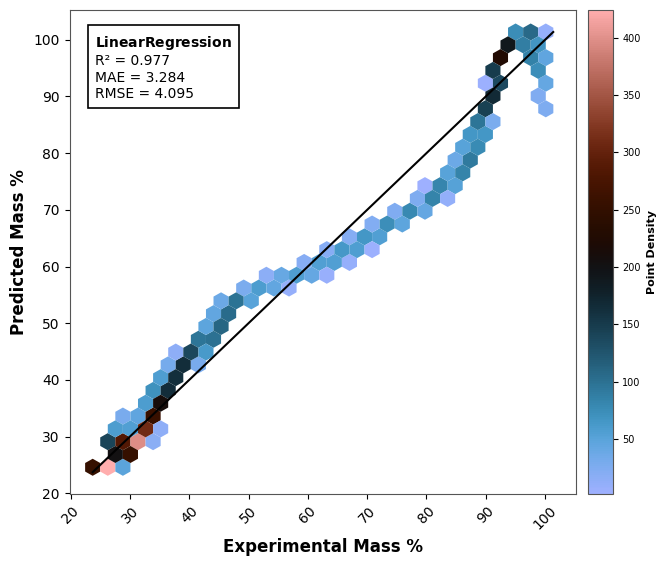

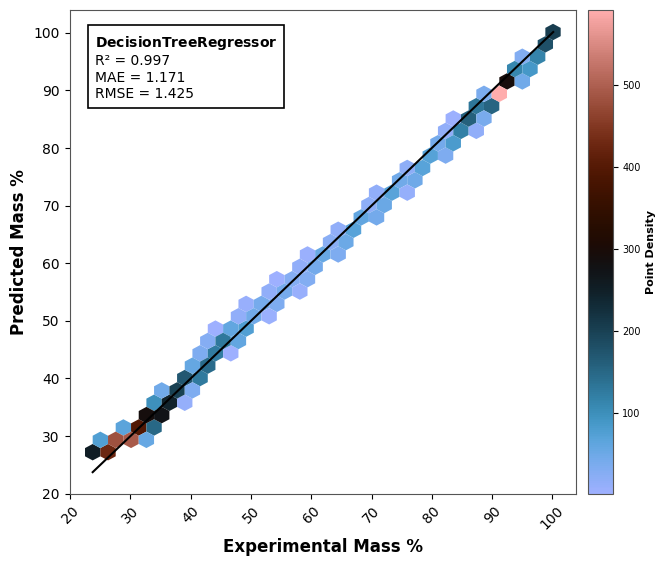

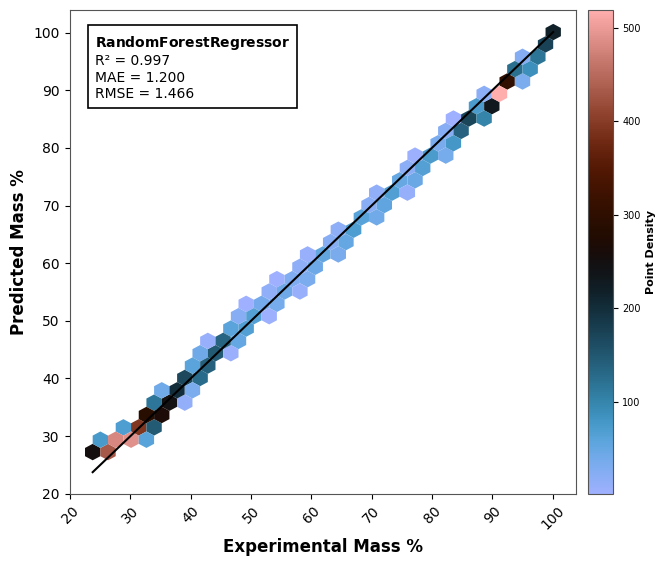

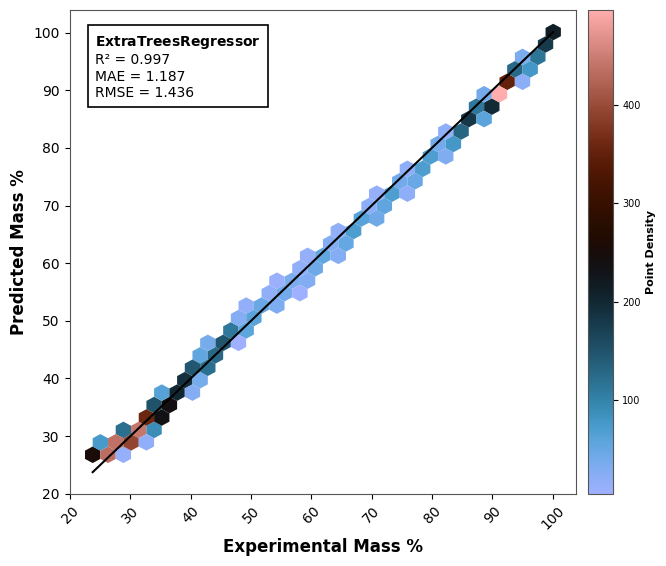

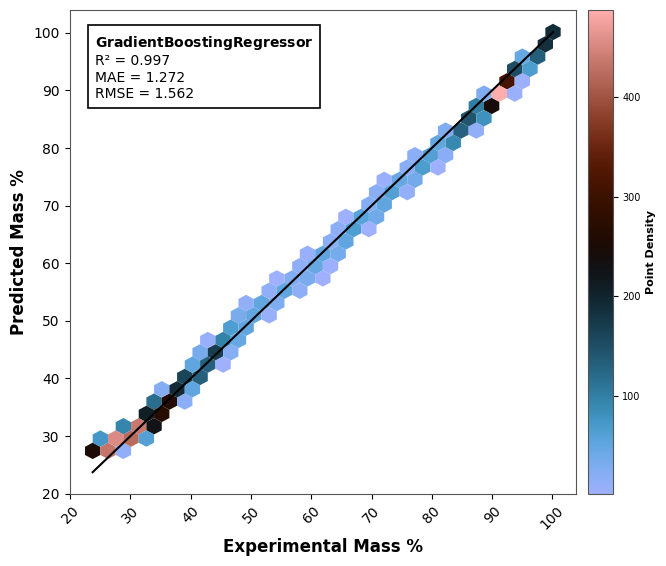

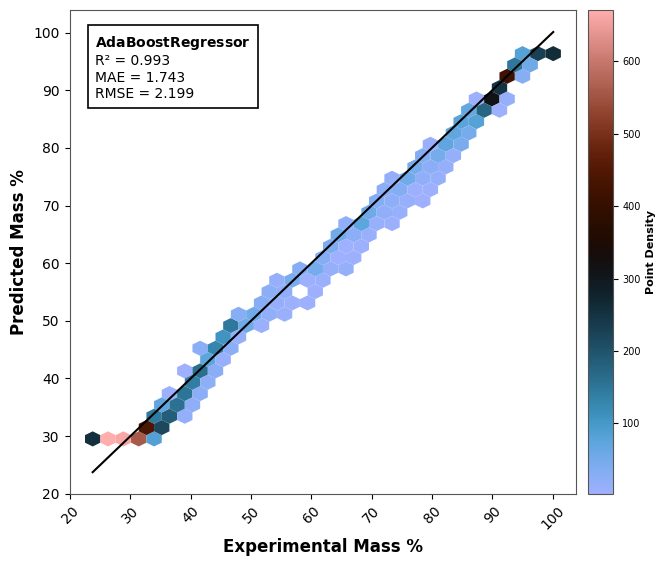

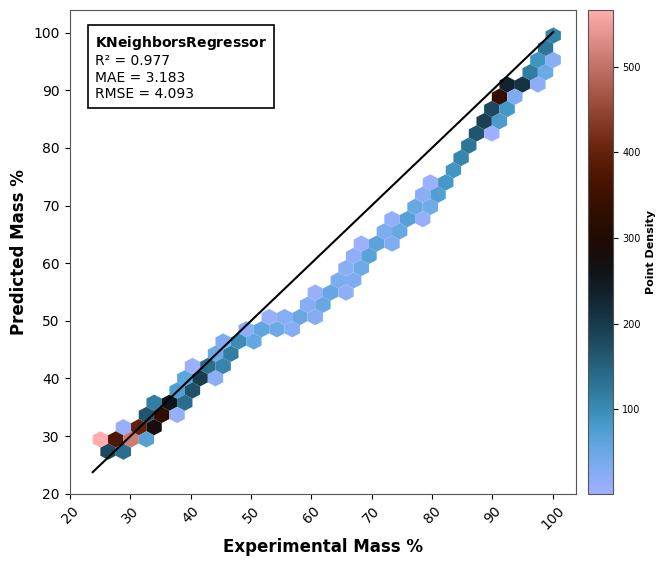

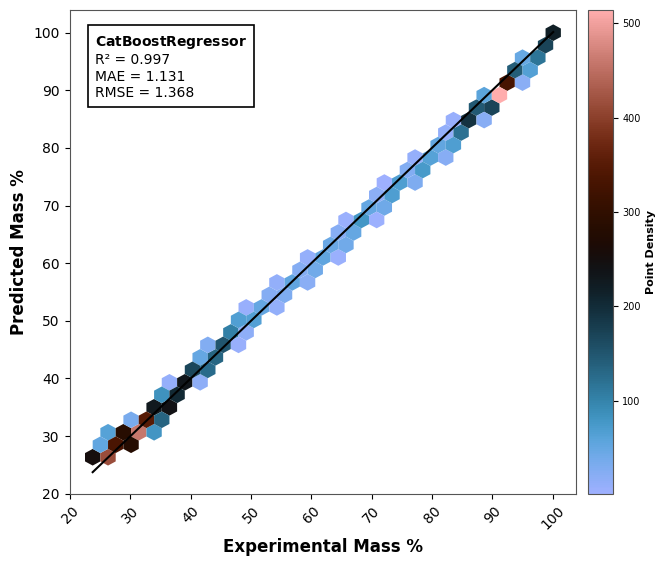

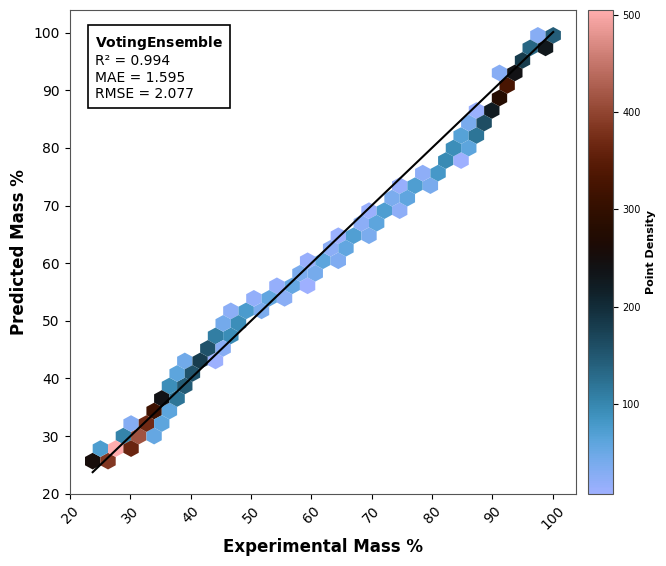

In [22]:
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap


def plot_density_parity_subplot(fig, ax, y_true, y_pred, model_name, r2, mae, rmse):
    hb = ax.hexbin(y_true, y_pred, gridsize=30, cmap=BERLIN_CMAP, mincnt=1, edgecolors='none')
    cbar = fig.colorbar(hb, ax=ax, pad=0.02)
    cbar.set_label('Point Density', fontweight='bold', fontsize=8)
    cbar.ax.tick_params(labelsize=7)
    min_val = min(min(y_true), min(y_pred))
    max_val = max(max(y_true), max(y_pred))
    
    ax.plot([min_val, max_val], [min_val, max_val], color="#010101", linewidth=1.5)
    ax.set_xlabel('Experimental Mass %', fontweight='bold', fontsize=12)
    ax.set_ylabel('Predicted Mass %', fontweight='bold', fontsize=12)
    ax.tick_params(axis='x', labelrotation=45, labelsize=10)
    ax.tick_params(axis='y', labelsize=10)
    
    text_str = (
    rf'$\mathbf{{{model_name}}}$' +
    f'\nR\u00b2 = {r2:.3f}\nMAE = {mae:.3f}\nRMSE = {rmse:.3f}'
)

    ax.text(
    0.05, 0.95, text_str,
    transform=ax.transAxes,
    fontsize=10,
    fontweight='normal',
    verticalalignment='top',
    bbox=dict(
        boxstyle='square,pad=0.5',
        facecolor='white',
        edgecolor='black',
        linewidth=1.2
    )
)
    ax.grid(False)
# --- BUILD SEPARATE FIGURE PER MODEL ---
for name, data in predictions_store.items():
    fig, ax = plt.subplots(figsize=(7, 6))
    fig.patch.set_facecolor('white')

    if data.get("error") is not None:
        ax.text(0.05, 0.95, f"{name} (Error)\nError: {data['error']}",
                transform=ax.transAxes, ha='left', va='top',
                color='red', fontsize=8, fontweight='bold')
        ax.set_title("")
    else:
        plot_density_parity_subplot(fig, ax, data["y_true"], data["y_pred"],
                                     name, data["r2"], data["mae"], data["RMSE"])

    plt.tight_layout(rect=[0, 0.02, 1, 0.98])
    plt.show()
    plt.close()

### TGA Profile 

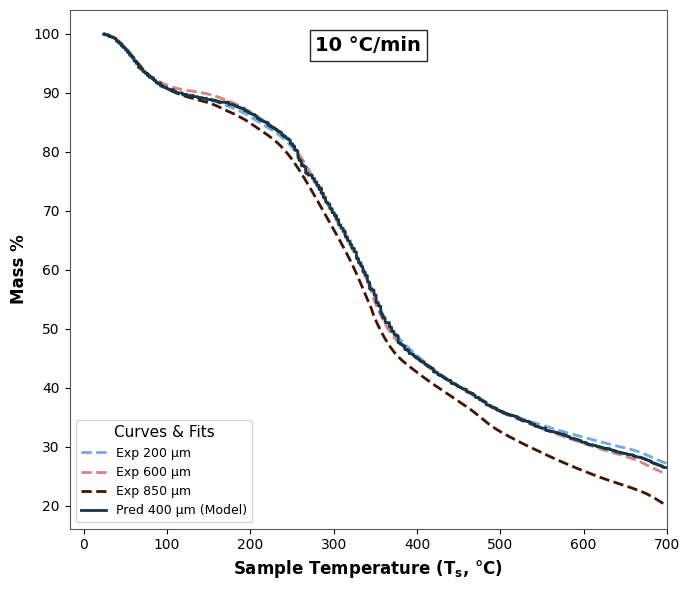

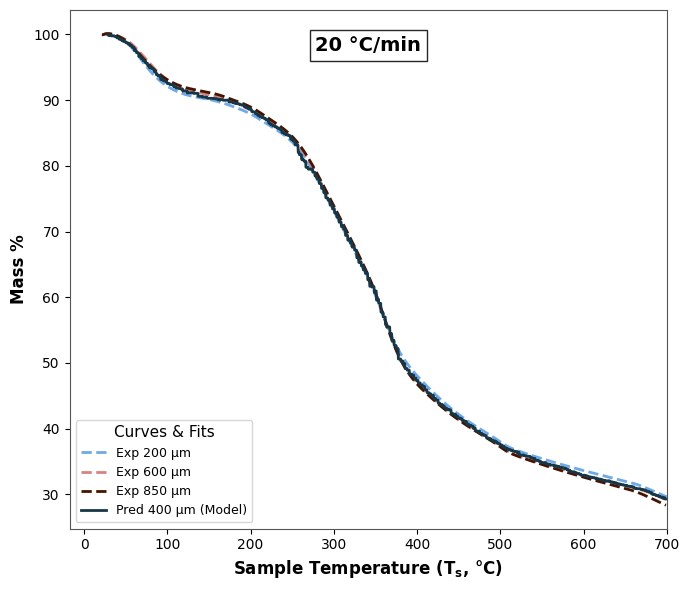

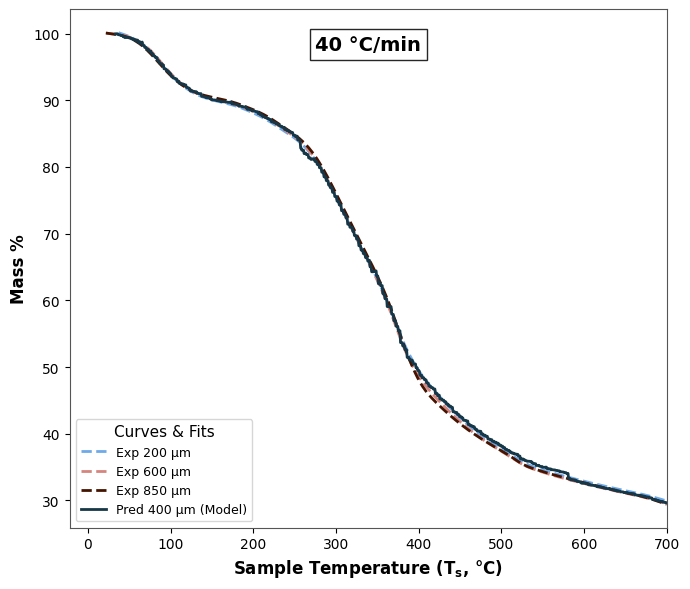

In [23]:

# Define heating rates and sizes available in your dataset
heating_rates = [10, 20, 40]
sizes = [200, 600, 850]  # Add or adjust based on your actual training sizes

# --- CHANGED: Rich, solid, high-contrast dark color palette ---
_berlin_vals = np.linspace(0.08, 0.92, 4)
colors_size = {
    200: BERLIN_CMAP(_berlin_vals[0]),
    600: BERLIN_CMAP(_berlin_vals[3]),
    850: BERLIN_CMAP(_berlin_vals[2]),
    400: BERLIN_CMAP(_berlin_vals[1])   #(Reserved for 400 µm Prediction)
}

for rate in heating_rates:
    # 1. Create a completely separate standalone figure for each heating rate
    fig, ax = plt.subplots(figsize=(7, 6))
    fig.patch.set_facecolor('white') 
    # 2. Plot existing experimental lines from training data (200, 600, 850 µm)
    for size in sizes:
        curve = train_data[(train_data['size'] == size) & (train_data['heating_rate'] == rate)]
        if not curve.empty:
            ax.plot(curve['Ts'], curve['mass_percent'],
                    label=f'Exp {size} µm',
                    color=colors_size.get(size, '#000000'),
                    linewidth=2.0,   # Slightly thicker for better visibility
                    linestyle='--')  # Alpha removed completely for full opacity

    # 3. Load the experimental 400 µm data from text files and overlay it
    file_name = f'g-400-{rate}.txt'
    try:
        # Use the robust load_tga_file function
        df_exp_400 = load_tga_file(file_name, 400, rate)
        df_exp_400['mass_percent_exp'] = df_exp_400['mass_percent']

        # 4. Generate and overlay the direct winning model prediction for 400 µm
        X_predict_base = pd.DataFrame({
            'Ts': df_exp_400['Ts'],
            'size': 400,
            'heating_rate': rate
        })
        # Apply feature engineering and select features
        X_predict = add_engineered_features(X_predict_base)[features]

        y_pred_400 = best_model_instance.predict(X_predict)

        # --- PLOT MODEL PREDICTION (Solid Dark Red Line) ---
        ax.plot(df_exp_400['Ts'], y_pred_400,
                label='Pred 400 µm (Model)',
                color=colors_size[400],  # Dark Red
                linewidth=2.0,           # Strong thickness to serve as the main focus
                linestyle='-')

    except FileNotFoundError:
        print(f"Warning: '{file_name}' was not found. Skipping 400 µm curves for this rate.")
    except Exception as e:
        print(f"Error reading '{file_name}': {e}")

    # Set x-axis limit to 700 degrees Celsius
    ax.set_xlim(right=700)

    # --- DESIGN AND STYLING REQUIREMENTS ---

    # 1. Title INSIDE the Graph Area (Top Center)
    ax.text(0.5, 0.95, f'{rate} °C/min',
            transform=ax.transAxes,
            fontsize=14,
            fontweight='bold',
            color='#000000',
            ha='center',
            va='top',
            bbox=dict(facecolor='white', alpha=0.9, edgecolor="#100F0F", pad=4))

    # 2. Bold Axis Labels
    ax.set_xlabel("Sample Temperature ($\mathbf{T_s}$, °C)", fontweight='bold', fontsize=12, color='#000000')
    ax.set_ylabel('Mass %', fontweight='bold', fontsize=12, color='#000000')

    # 3. Bold Tick Labels
    plt.setp(ax.get_xticklabels(), color='#000000')
    plt.setp(ax.get_yticklabels(), color='#000000')

    # 4. No Grid Lines
    ax.grid(False)

    # 5. Bold Legend Box (Title and Entry Labels)
    ax.legend(title="Curves & Fits",
              title_fontsize=11,
              loc='lower left',
              prop={'weight': 'normal', 'size': 9})

    plt.tight_layout()
    plt.show()
    plt.close()


### Experimental Vs Predicted for 400 µm

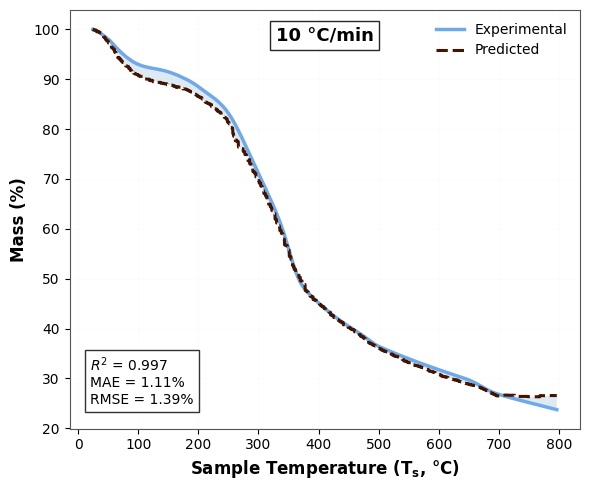

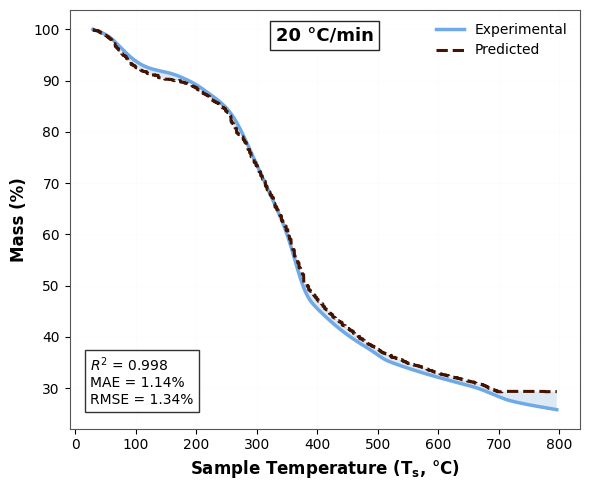

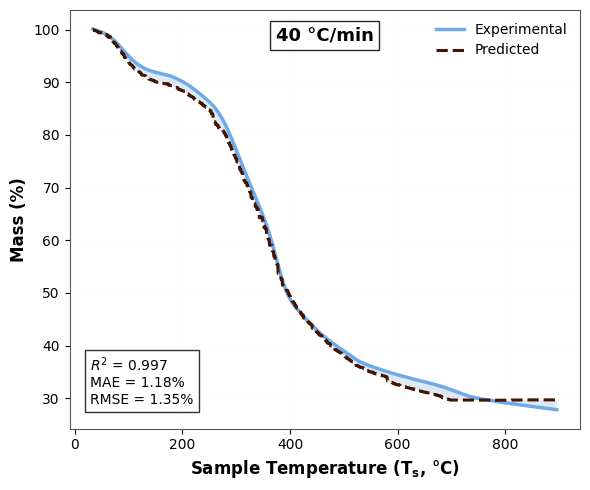

In [26]:
rates = [10, 20, 40]

for rate in rates:
    fig, a = plt.subplots(figsize=(6, 5))

    df = load_tga_file(f'g-400-{rate}.txt', 400, rate)
    X_base = df[['Ts', 'size', 'heating_rate']]
    Xp = add_engineered_features(X_base)[features]
    yp = best_model_instance.predict(Xp)
    ye = df['mass_percent'].values
    T = df['Ts'].values

    a.plot(T, ye, lw=2.5, label='Experimental', color=BERLIN_CMAP(_berlin_vals[0]))
    a.plot(T, yp, '--', lw=2.2, label='Predicted', color=BERLIN_CMAP(_berlin_vals[2]))
    a.fill_between(T, ye, yp, alpha=.15)
    
    a.legend(loc='upper right', frameon=True, fancybox=False,
                 edgecolor='black', facecolor='white', framealpha=1, fontsize=11)
    
    r2 = r2_score(ye, yp)
    mae = mean_absolute_error(ye, yp)
    rmse = np.sqrt(mean_squared_error(ye, yp))

    a.text(
    .04, .06,
    f'$R^2$ = {r2:.3f}\nMAE = {mae:.2f}%\nRMSE = {rmse:.2f}%',
    transform=a.transAxes,
    fontsize=10,
    bbox=dict(facecolor='white', alpha=.85, edgecolor="#100F0F"))

    # --- Rate label INSIDE the plot, top area, temp only ---
    a.text(
        .5, .96,
        f'{rate} °C/min',
        transform=a.transAxes,
        fontsize=13,
        fontweight='bold',
        ha='center', va='top',
        bbox=dict(facecolor='white', alpha=0.9, edgecolor="#100F0F", pad=4)
    )

    a.set_xlabel("Sample Temperature ($\mathbf{T_s}$, °C)", fontsize=12, fontweight='bold')
    a.set_ylabel('Mass (%)', fontsize=12, fontweight='bold')
    a.grid(alpha=.03)
    a.legend(frameon=False, fontsize=10)

    plt.tight_layout()
    plt.show()
    plt.close()

### Export Predicted files

In [25]:
initial_weight_assumed = 10.0
for rate in heating_rates:
    Ts_real = train_data[(train_data['size'] == 600) & (train_data['heating_rate'] == rate)]['Ts'].values
    if len(Ts_real) == 0:
        continue

    X_pred_base = pd.DataFrame({'Ts': Ts_real, 'size': 400, 'heating_rate': rate})
    # Apply feature engineering and select features
    X_pred = add_engineered_features(X_pred_base)[features]
    predicted_mass_percent = best_model_instance.predict(X_pred)

    Weight = (predicted_mass_percent / 100.0) * initial_weight_assumed
    Index = np.arange(1, len(Ts_real) + 1)
    t = (Ts_real - Ts_real[0]) * 60 / rate
    HF = np.zeros_like(Ts_real)
    Tr = Ts_real + np.random.normal(0, 0.5, len(Ts_real))

    export_df = pd.DataFrame({
        'Index': Index, 'Ts': Ts_real, 't': t, 'HF': HF, 'Weight': Weight, 'Tr': Tr
    })

    filename = f"predicted_NoCV_withFE_resampled_g-400-{rate}.txt"
    with open(filename, 'w', encoding='utf-8') as f:
        f.write("         Index            Ts             t            HF        Weight            Tr\n")
        f.write("           [#]          [°C]           [s]          [mW]          [mg]          [°C]\n")

        for _, row in export_df.iterrows():
            f.write(f" {int(row['Index']):>13} {row['Ts']:>13.5e} {row['t']:>13.5e} {row['HF']:>13.5e} {row['Weight']:>13.5e} {row['Tr']:>13.5e}\n")

        f.write(f"MICS 400-{rate}, predicted {best_model_name}\n")

print("\nPipeline execution completed successfully.")


Pipeline execution completed successfully.
